# Email Spam Detection: Fine-tuning DistilBERT
Step 1 of the live mail detector. Runs on Google Colab (free GPU).

**Before running:** Runtime > Change runtime type > **T4 GPU**.

In [2]:
!pip install -q transformers datasets evaluate accelerate scikit-learn matplotlib seaborn
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: True


## 1. Load the dataset (Enron-Spam, real emails)

In [3]:
from datasets import load_dataset
ds = load_dataset("SetFit/enron_spam")
print(ds)
print(ds["train"][0]["text"][:300])
print("Label counts:", {l: sum(1 for x in ds["train"]["label"] if x == l) for l in (0, 1)})

README.md:   0%|          | 0.00/176 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B /  101MB            

train.jsonl: downloading bytes:           |  0.00B            

test.jsonl: reconstructing file:   0%|          |  0.00B / 6.27MB            

test.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/31716 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['message_id', 'text', 'label', 'label_text', 'subject', 'message', 'date'],
        num_rows: 31716
    })
    test: Dataset({
        features: ['message_id', 'text', 'label', 'label_text', 'subject', 'message', 'date'],
        num_rows: 2000
    })
})
any software just for 15 $ - 99 $ understanding oem software
lead me not into temptation ; i can find the way myself .
# 3533 . the law disregards trifles .
Label counts: {0: 15553, 1: 16163}


## 2. Clean the text and create train / validation / test splits

In [4]:
import re
from datasets import DatasetDict

def clean(text):
    text = re.sub(r"<[^>]+>", " ", text or "")          # strip HTML tags
    text = re.sub(r"http\S+", " URL ", text)             # replace links with a token
    text = re.sub(r"\s+", " ", text).strip()
    return text

def prep(batch):
    return {"text": [clean(t) for t in batch["text"]]}

ds = ds.map(prep, batched=True)
split = ds["train"].train_test_split(test_size=0.1, seed=42)
data = DatasetDict({"train": split["train"], "validation": split["test"], "test": ds["test"]})
print({k: len(v) for k, v in data.items()})

Map:   0%|          | 0/31716 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

{'train': 28544, 'validation': 3172, 'test': 2000}


## 3. Tokenize

In [5]:
from transformers import AutoTokenizer, DataCollatorWithPadding

MODEL = "distilbert-base-uncased"   # swap for "microsoft/Multilingual-MiniLM-L12-H384" or "google/muril-base-cased" later
tokenizer = AutoTokenizer.from_pretrained(MODEL)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

tokenized = data.map(tokenize, batched=True)
tokenized = tokenized.remove_columns([c for c in tokenized["train"].column_names if c not in ("input_ids", "attention_mask", "label")])
collator = DataCollatorWithPadding(tokenizer)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/28544 [00:00<?, ? examples/s]

Map:   0%|          | 0/3172 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

## 4. Fine-tune

In [6]:
import numpy as np
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=2, id2label={0: "ham", 1: "spam"}, label2id={"ham": 0, "spam": 1}
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1}

args = TrainingArguments(
    output_dir="spam-distilbert",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",          # use evaluation_strategy on older transformers versions
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.040077,0.028108,0.991803,0.989647,0.994492,0.992063
2,0.005652,0.029688,0.993064,0.995086,0.991432,0.993256


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3568, training_loss=0.035327578289225496, metrics={'train_runtime': 396.0423, 'train_samples_per_second': 144.146, 'train_steps_per_second': 9.009, 'total_flos': 3781062495506496.0, 'train_loss': 0.035327578289225496, 'epoch': 2.0})

## 5. Evaluate on the held-out test set

              precision    recall  f1-score   support

         ham     0.9909    0.9929    0.9919       992
        spam     0.9930    0.9911    0.9921      1008

    accuracy                         0.9920      2000
   macro avg     0.9920    0.9920    0.9920      2000
weighted avg     0.9920    0.9920    0.9920      2000

ROC-AUC: 0.9995


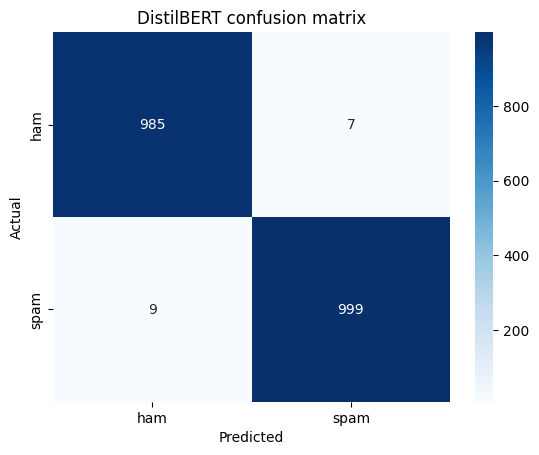

In [7]:
import seaborn as sns, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from scipy.special import softmax

out = trainer.predict(tokenized["test"])
probs = softmax(out.predictions, axis=-1)[:, 1]
preds = (probs >= 0.5).astype(int)
y = out.label_ids

print(classification_report(y, preds, target_names=["ham", "spam"], digits=4))
print("ROC-AUC:", round(roc_auc_score(y, probs), 4))

sns.heatmap(confusion_matrix(y, preds), annot=True, fmt="d", cmap="Blues",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("DistilBERT confusion matrix")
plt.show()

## 6. Threshold tuning
A spam filter should avoid **false positives** (real mail sent to spam). Pick the lowest threshold that keeps precision high.

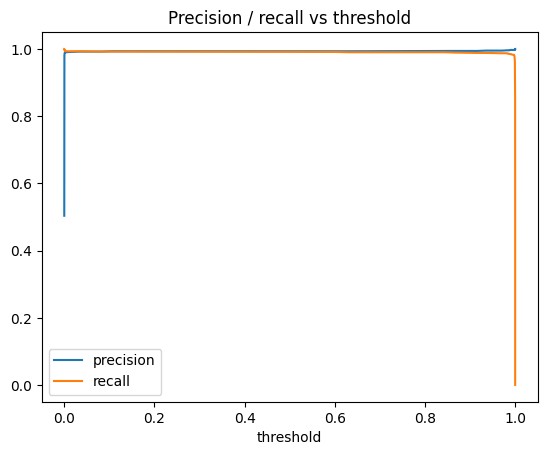

threshold 0.50  precision 0.9930  recall 0.9911  f1 0.9921
threshold 0.70  precision 0.9940  recall 0.9901  f1 0.9920
threshold 0.90  precision 0.9940  recall 0.9881  f1 0.9910
threshold 0.95  precision 0.9950  recall 0.9871  f1 0.9910


In [8]:
from sklearn.metrics import precision_recall_curve
prec, rec, thr = precision_recall_curve(y, probs)
plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall")
plt.xlabel("threshold"); plt.legend(); plt.title("Precision / recall vs threshold"); plt.show()

for t in (0.5, 0.7, 0.9, 0.95):
    p = (probs >= t).astype(int)
    pr, rc, f, _ = precision_recall_fscore_support(y, p, average="binary")
    print(f"threshold {t:.2f}  precision {pr:.4f}  recall {rc:.4f}  f1 {f:.4f}")

## 7. Try it on your own emails

In [9]:
from transformers import pipeline
clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer,
               device=0 if torch.cuda.is_available() else -1, top_k=None, truncation=True, max_length=256)

def predict(text):
    scores = {d["label"]: d["score"] for d in clf(clean(text))[0]}
    return {"spam_probability": round(scores["spam"], 4), "label": "spam" if scores["spam"] >= 0.5 else "ham"}

print(predict("Dear customer, your account is suspended. Verify now at http://secure-login.xyz to avoid closure."))
print(predict("Hi team, attaching the notes from Monday's meeting. Let's sync on Thursday."))

{'spam_probability': 0.9998, 'label': 'spam'}
{'spam_probability': 0.0001, 'label': 'ham'}


## 8. Save the model (to Google Drive + zip)

In [10]:
from google.colab import drive
drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/email-spam-distilbert"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Saved to", SAVE_DIR)

# optional: download as a zip
!cd /content/drive/MyDrive && zip -r -q email-spam-distilbert.zip email-spam-distilbert

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/email-spam-distilbert


## Next steps
1. Test on **your own labelled emails** (the honest check for real-world performance).
2. Build the Gmail fetcher + email parser (next step of the project).
3. Add the hybrid layer: link count, SPF/DKIM results, sender mismatch.
4. Add explanations (SHAP / LIME) to show *why* an email was flagged.